# 不等式制約下の凸二次計画問題 ― 主問題・双対問題・KKT条件を実験で理解する

**教科書の付録 A.2（246〜255ページ）をもとにした学習用ノートブック**です。特に**例題 A.2 / A.3**を実際に再現します。

### 到達目標

1. 制約付き最小化を「点から実行可能領域への射影」として理解する。
2. ラグランジュ関数から双対目的関数を途中式付きで導出できる。
3. `H = A @ A.T` がグラム行列であり半正定値になる理由を説明できる。
4. **KKT条件の4種類**を数値で検証する。
5. 教科書の例題A.2では「1つの制約だけが効く」、例題A.3では「2つの制約が効く」ことを説明できる。

**必要なライブラリ**：NumPy、Matplotlib、SciPy（Colab / Jupyter で利用可能）。

> 記号：教科書と同様に、制約を $g_i(x)=a_{i0}+a_i^Tx\le 0$ と置きます。コードでは行列 `A` の各行が $a_i^T$、配列 `a0` が $a_{i0}$ です。

## 1. 問題の定義：何を最小化するのか？

教科書の例題 A.1 は

$$
\min_{x\in\mathbb{R}^d} f(x)=\frac12\|x-c\|^2
\quad\text{subject to}\quad
 g_i(x)=a_{i0}+a_i^Tx\le0\;(i=1,\dots,m).
$$

- $c$ は最小化したい関数の中心（制約がなければ解は $x=c$）。
- **実行可能領域**は全制約を同時に満たす点の集合。
- $f(x)$ は $x$ と $c$ の距離の二乗の半分なので、解は**実行可能領域内で $c$ に最も近い点**。

二次計画問題の一般形 $\tfrac12x^TQx+v^Tx$ と比較すると、この例では $Q=I,\ v=-c$（定数 $\|c\|^2/2$ を除く）です。$I$ は正定値なので目的関数は厳密凸です。

**注意**：一般の凸二次計画問題では、$Q$ は正定値でなくても**半正定値**なら凸になります。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

np.set_printoptions(precision=6, suppress=True)

# 教科書の式 (A.2.32) ～ (A.2.34)
# g1(x)= x1+x2-4 <= 0
# g2(x)=-2x1+x2-4 <= 0
# g3(x)= x1-5x2+2 <= 0
A = np.array([[1., 1.], [-2., 1.], [1., -5.]])
a0 = np.array([-4., -4., 2.])

def g(x):
    return A @ np.asarray(x) + a0

def objective(x, c):
    x = np.asarray(x)
    return 0.5 * np.dot(x-c, x-c)

def objective_grad(x, c):
    return np.asarray(x) - c

print('A =\n', A)
print('a0 =', a0)
print('制約 g_i(x) <= 0：', ['x1+x2-4', '-2*x1+x2-4', 'x1-5*x2+2'])

A =
 [[ 1.  1.]
 [-2.  1.]
 [ 1. -5.]]
a0 = [-4. -4.  2.]
制約 g_i(x) <= 0： ['x1+x2-4', '-2*x1+x2-4', 'x1-5*x2+2']


## 2. ラグランジュ関数とKKT条件（教科書 A.2.2〜A.2.7）

非負の乗数 $\lambda_i\ge0$ を導入すると

$$
L(x,\lambda)=\frac12\|x-c\|^2+\sum_{i=1}^m\lambda_i(a_{i0}+a_i^Tx).
$$

KKT条件は次の**4種類**です（教科書では式が4行）：

| 条件 | この問題の式 | 直感 |
|---|---|---|
| 停留条件 | $x-c+\sum_i\lambda_i a_i=0$ | 目的関数と制約の勾配が釣り合う |
| 主実行可能性 | $g_i(x)\le0$ | 解は制約領域の中 |
| 双対実行可能性 | $\lambda_i\ge0$ | 乗数は非負 |
| 相補性 | $\lambda_i g_i(x)=0$ | 制約に余裕があれば、その乗数は0 |

停留条件を整理すると、

$$\boxed{x^*=c-\sum_i\lambda_i^*a_i=c-A^T\lambda^*} \tag{A.2.22}$$

です。つまり、中心 $c$ から制約の法線ベクトルの線形結合を引いて最適点に到達します。

> **教科書の注意を補足**：相補性より「$g_i(x^*)<0\Rightarrow\lambda_i^*=0$」および「$\lambda_i^*>0\Rightarrow g_i(x^*)=0$」です。ただし **$g_i(x^*)=0$ でも $\lambda_i^*=0$ はあり得ます**。すべての場合に厳密な2択になるわけではありません。

## 3. 主問題から双対問題への導出（教科書 A.2.20〜A.2.27）

行列 $A$ は $m\times d$、$a_0=(a_{10},\dots,a_{m0})^T$ とします。

ラグランジュ関数は

$$L(x,\lambda)=\tfrac12(x-c)^T(x-c)+\lambda^T(a_0+Ax).$$

**ステップ 1**：$x$ について最小化（停留条件）

$$\nabla_x L=x-c+A^T\lambda=0 \quad\Longrightarrow\quad x(\lambda)=c-A^T\lambda.$$

**ステップ 2**：$x(\lambda)$ を $L$ に代入

$$
\begin{aligned}
D(\lambda)&=\inf_x L(x,\lambda)\\
&=\tfrac12\|A^T\lambda\|^2+\lambda^T\bigl(a_0+A(c-A^T\lambda)\bigr)\\
&=\tfrac12\lambda^TAA^T\lambda+\lambda^T(a_0+Ac)-\lambda^TAA^T\lambda\\
&=\boxed{-\tfrac12\lambda^TH\lambda+\lambda^Tq},
\end{aligned}
$$

ここで

$$\boxed{H=AA^T,\qquad q=a_0+Ac}$$

です。

**ステップ 3**：双対問題

$$
\boxed{\max_{\lambda\ge0}D(\lambda)= -\tfrac12\lambda^TH\lambda+q^T\lambda.}
$$

この問題の双対制約は $\lambda\ge0$ だけです。SVMの双対問題に $\lambda^Tb=0$ という追加制約があったのは、SVMには**バイアス $w_0$**という別の消去対象があったためです。

$H=AA^T$ は制約の法線ベクトルの**グラム行列**なので、任意の $v$ に対して

$$v^THv=\|A^Tv\|^2\ge0.$$

よって $H$ は半正定値、$D$ は凹二次関数です。

In [2]:
H = A @ A.T
print('H =\n', H)
print('H の固有値 =', np.linalg.eigvalsh(H))
assert np.all(np.linalg.eigvalsh(H) > -1e-10)
assert np.allclose(H, np.array([[2, -1, -4], [-1, 5, -7], [-4, -7, 26]]))
print('教科書 (A.2.37) の H と一致します。')

H =
 [[ 2. -1. -4.]
 [-1.  5. -7.]
 [-4. -7. 26.]]
H の固有値 = [ 0.        4.406613 28.593387]
教科書 (A.2.37) の H と一致します。


## 4. 主問題・双対問題をSciPyで解く

計算では**主問題と双対問題を別々に解き**、結果が一致するか検証します。

- 主問題：$\min\frac12\|x-c\|^2$、制約 $g(x)\le0$。
- 双対問題：$\max D(\lambda)$、制約 $\lambda\ge0$。
- 目的関数値の差（duality gap）と、4種類のKKT条件を数値チェックします。

双対問題を `scipy.optimize.minimize` に渡す際は、$-D(\lambda)$ を最小化します。

In [3]:
def solve_primal(c):
    c = np.asarray(c, dtype=float)
    return minimize(
        lambda x: objective(x, c),
        x0=np.array([0.0, 1.0]),
        jac=lambda x: objective_grad(x, c),
        constraints=[{
            'type': 'ineq',
            'fun': lambda x: -g(x),
            'jac': lambda x: -A,
        }],
        method='SLSQP',
        options={'ftol': 1e-12, 'maxiter': 1000},
    )

def solve_dual(c):
    c = np.asarray(c, dtype=float)
    q = a0 + A @ c
    result = minimize(
        fun=lambda lam: 0.5 * lam @ H @ lam - q @ lam,
        x0=np.zeros(3),
        jac=lambda lam: H @ lam - q,
        bounds=[(0.0, None)]*3,
        method='SLSQP',
        options={'ftol': 1e-12, 'maxiter': 1000},
    )
    return result

def analyze_case(c, title=''):
    c = np.asarray(c, dtype=float)
    primal = solve_primal(c)
    dual = solve_dual(c)
    assert primal.success, primal.message
    assert dual.success, dual.message
    x_p = primal.x
    lam = np.maximum(dual.x, 0.0)
    x_recovered = c - A.T @ lam
    q = a0 + A @ c
    pval = objective(x_p, c)
    dval = q @ lam - 0.5 * lam @ H @ lam
    gap = pval - dval
    print('===', title, '===')
    print('中心 c                 =', c)
    print('主問題の最適解 x*       =', x_p)
    print('双対解 λ*              =', lam)
    print('双対解から復元した x*    =', x_recovered)
    print('制約 g_i(x*)           =', g(x_p))
    print('主問題の最小値         =', pval)
    print('双対問題の最大値       =', dval)
    print('双対ギャップ           =', gap)
    print('相補性 λ_i g_i(x*)      =', lam * g(x_p))
    print('停留条件の残差         =', x_p - c + A.T @ lam)
    print('正の乗数の制約番号     =', list(np.flatnonzero(lam > 1e-7) + 1))
    assert np.all(g(x_p) <= 1e-6)
    assert np.all(lam >= -1e-8)
    assert np.linalg.norm(x_p - x_recovered) < 1e-5
    assert abs(gap) < 1e-6
    assert np.max(np.abs(lam*g(x_p))) < 1e-5
    return {'c': c, 'x': x_p, 'lambda': lam, 'pval': pval, 'dval': dval, 'gap': gap}

## 5. 例題 A.2：中心 $c=(2,4)^T$ を制約領域へ射影する

教科書252〜254ページ。最適化問題は

$$
\min\frac12[(x_1-2)^2+(x_2-4)^2]
$$

$$
\begin{cases}
 x_1+x_2-4\le0\\
 -2x_1+x_2-4\le0\\
 x_1-5x_2+2\le0.
\end{cases}
$$

教科書の結果は

$$\lambda^*=(1,0,0)^T,\quad x^*=(1,3)^T,\quad f(x^*)=1.$$

第1制約だけが等号で成立し、他の制約には余裕があります。**これを手計算・数値計算・図で確認**します。

In [4]:
case_A2 = analyze_case([2,4], title='例題 A.2')
assert np.allclose(case_A2['lambda'], [1,0,0], atol=1e-6)
assert np.allclose(case_A2['x'], [1,3], atol=1e-6)
assert np.isclose(case_A2['pval'], 1.0)

=== 例題 A.2 ===
中心 c                 = [2. 4.]
主問題の最適解 x*       = [1. 3.]
双対解 λ*              = [1. 0. 0.]
双対解から復元した x*    = [1. 3.]
制約 g_i(x*)           = [ -0.  -3. -12.]
主問題の最小値         = 1.0000000000000018
双対問題の最大値       = 1.0
双対ギャップ           = 1.7763568394002505e-15
相補性 λ_i g_i(x*)      = [-0. -0. -0.]
停留条件の残差         = [-0. -0.]
正の乗数の制約番号     = [np.int64(1)]


### 図で確認：実行可能領域、等高線、最適解

- 灰色の領域：3つの不等式をすべて満たす点。
- 等高線：中心 $c$ からの距離の二乗が同じ点。
- ×：制約のない最小点 $c$。
- ★：制約付き最適解 $x^*$。
- 強調した制約直線：$\lambda_i>0$ の制約。

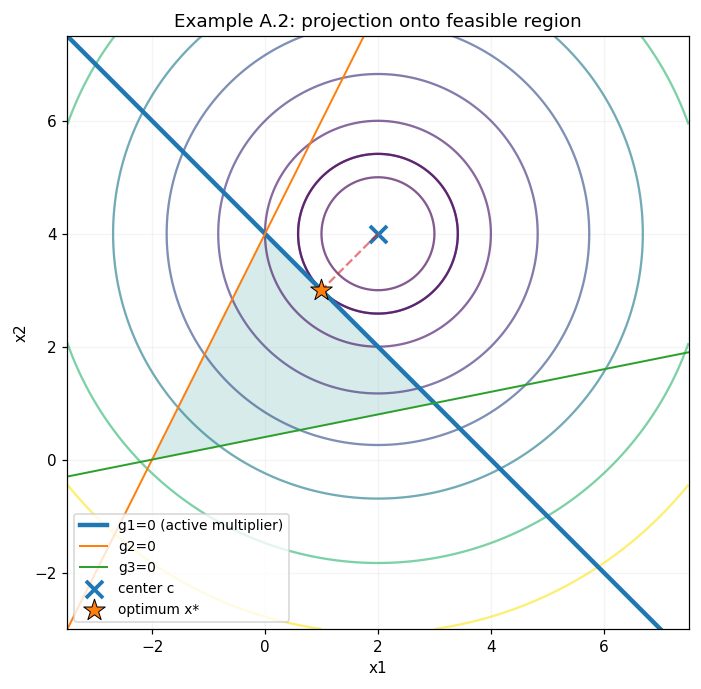

In [5]:
def plot_case(result, title, xlim=(-3.5, 7.5), ylim=(-3.0, 7.5)):
    c, xstar, lam = result['c'], result['x'], result['lambda']
    x1 = np.linspace(*xlim, 350)
    x2 = np.linspace(*ylim, 350)
    XX, YY = np.meshgrid(x1, x2)
    feasible = np.ones_like(XX, dtype=bool)
    for i in range(3):
        feasible &= (a0[i] + A[i,0]*XX + A[i,1]*YY <= 0)
    Z = 0.5*((XX-c[0])**2+(YY-c[1])**2)
    fig, ax = plt.subplots(figsize=(8, 7))
    ax.contourf(XX, YY, feasible.astype(int), levels=[0.5,1.5], alpha=.18)
    vals = np.unique(np.r_[max(result['pval'],0.1), [0.5, 1,2,4,7,11,17,25]])
    vals = np.sort(vals)
    ax.contour(XX,YY,Z,levels=vals, alpha=.65)
    for i in range(3):
        yy = (-a0[i]-A[i,0]*x1)/A[i,1]
        ax.plot(x1, yy, linewidth=2.9 if lam[i]>1e-6 else 1.3,
                label=f'g{i+1}=0'+(' (active multiplier)' if lam[i]>1e-6 else ''))
    ax.scatter(*c, marker='x', s=125, linewidths=2.5, label='center c')
    ax.scatter(*xstar, marker='*', s=220, edgecolors='k', linewidths=.65, label='optimum x*', zorder=10)
    ax.plot([c[0],xstar[0]],[c[1],xstar[1]],'--',alpha=.6)
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_aspect('equal',adjustable='box'); ax.set_xlabel('x1'); ax.set_ylabel('x2')
    ax.set_title(title); ax.grid(alpha=.13); ax.legend(loc='lower left', fontsize=9)
    plt.show()

plot_case(case_A2, 'Example A.2: projection onto feasible region')

### 例題 A.2 のKKT条件を手計算で確認

$$x^*=(1,3),\quad c=(2,4),\quad \lambda^*=(1,0,0).$$

**停留条件**：$x^*-c+A^T\lambda^*=(-1,-1)+(1,1)=(0,0)$。

**主実行可能性**：$g(x^*)=(0,-3,-12)\le0$。

**双対実行可能性**：$\lambda^*\ge0$。

**相補性**：$\lambda_i^*g_i(x^*)=(0,0,0)$。

第2, 第3制約は厳密な不等式で、乗数0。最適解は**第1制約の直線上の最近点**です。

## 6. 例題 A.3：中心を変えると、有効な制約も変わる

教科書254〜255ページには、**制約は同じ**で目的関数の中心を変えた2問が載っています。

- $f_1(x)=\frac12[(x_1-5)^2+(x_2-1)^2]$：教科書の解は $\lambda^*=(5/3,0,1/3)^T$、$x^*=(3,1)^T$。
- $f_2(x)=\frac12[(x_1-1)^2+(x_2-1)^2]$：同じ制約を使い、ここでは数値計算で解を確認します。

まず $f_1$ は、第1・第3制約がともに有効になります。

=== 例題 A.3: f1 ===
中心 c                 = [5. 1.]
主問題の最適解 x*       = [3. 1.]
双対解 λ*              = [1.666667 0.       0.333333]
双対解から復元した x*    = [3. 1.]
制約 g_i(x*)           = [-0. -9.  0.]
主問題の最小値         = 2.0000000000000036
双対問題の最大値       = 1.999999999999726
双対ギャップ           = 2.7755575615628914e-13
相補性 λ_i g_i(x*)      = [-0. -0.  0.]
停留条件の残差         = [-0. -0.]
正の乗数の制約番号     = [np.int64(1), np.int64(3)]


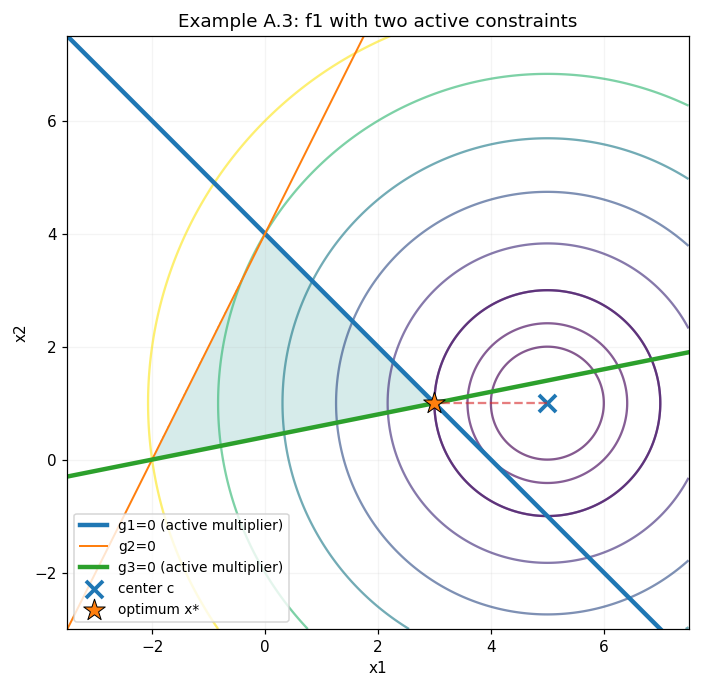

In [6]:
case_A3_f1 = analyze_case([5,1], '例題 A.3: f1')
assert np.allclose(case_A3_f1['lambda'], [5/3,0,1/3], atol=1e-6)
assert np.allclose(case_A3_f1['x'], [3,1], atol=1e-6)
assert np.isclose(case_A3_f1['pval'], 2.0, atol=1e-6)
plot_case(case_A3_f1, 'Example A.3: f1 with two active constraints')

### 手計算で $\lambda_1=5/3,\lambda_3=1/3$ を確かめる

この解では $g_1(x^*)=g_3(x^*)=0$、$g_2(x^*)<0$ です。

2本の直線の交点を求めると、

$$x_1+x_2=4,\quad x_1-5x_2=-2\quad\Longrightarrow\quad x^*=(3,1).$$

停留条件 $x^*=c-\lambda_1a_1-\lambda_3a_3$ に代入し、

$$
(3,1)=(5,1)-\lambda_1(1,1)-\lambda_3(1,-5).
$$

成分ごとに整理すると

$$\lambda_1+\lambda_3=2,\quad\lambda_1-5\lambda_3=0.$$

よって $\lambda_1=5/3,\ \lambda_3=1/3$、第2制約は余裕があるため $\lambda_2=0$ です。

=== 例題 A.3: f2 ===
中心 c                 = [1. 1.]
主問題の最適解 x*       = [1. 1.]
双対解 λ*              = [0. 0. 0.]
双対解から復元した x*    = [1. 1.]
制約 g_i(x*)           = [-2. -5. -2.]
主問題の最小値         = 0.0
双対問題の最大値       = 0.0
双対ギャップ           = 0.0
相補性 λ_i g_i(x*)      = [-0. -0. -0.]
停留条件の残差         = [0. 0.]
正の乗数の制約番号     = []


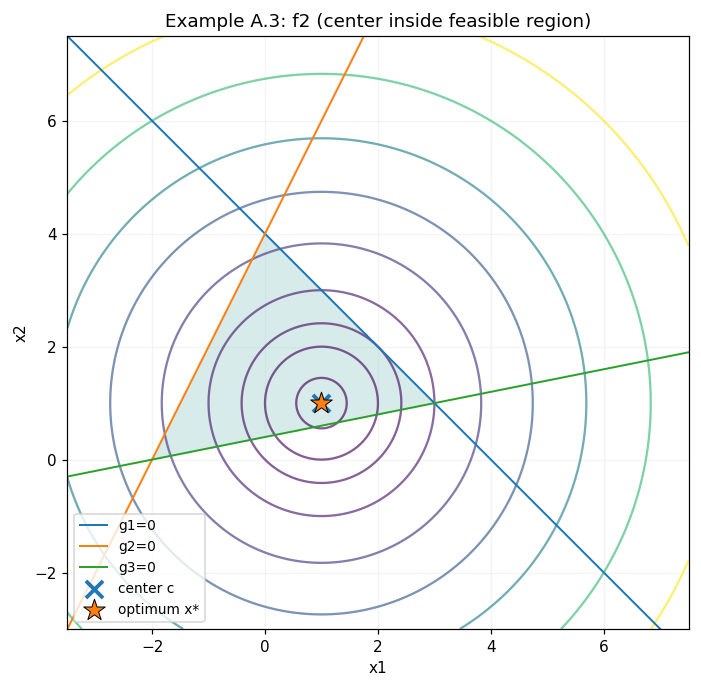

中心がすでに実行可能： True


In [7]:
case_A3_f2 = analyze_case([1,1], '例題 A.3: f2')
plot_case(case_A3_f2, 'Example A.3: f2 (center inside feasible region)')
print('中心がすでに実行可能：', np.all(g([1,1]) <= 0))

## 7. 双対関数は主問題の目的値の「下界」になる

任意の $\lambda\ge0$ と実行可能な $x$ では、制約 $g_i(x)\le0$ より

$$L(x,\lambda)=f(x)+\sum_i\lambda_i g_i(x)\le f(x).$$

また $D(\lambda)=\inf_z L(z,\lambda)$ なので

$$\boxed{D(\lambda)\le L(x,\lambda)\le f(x)}.$$

特に $D(\lambda)\le p^*$（主問題の最小値）。**最大化して下界をできる限り上げる**ことが双対問題の意味です。

この例では凸性と厳密実行可能点の存在（Slater条件）があるので強双対性が成り立ち、最適値は等しくなります。

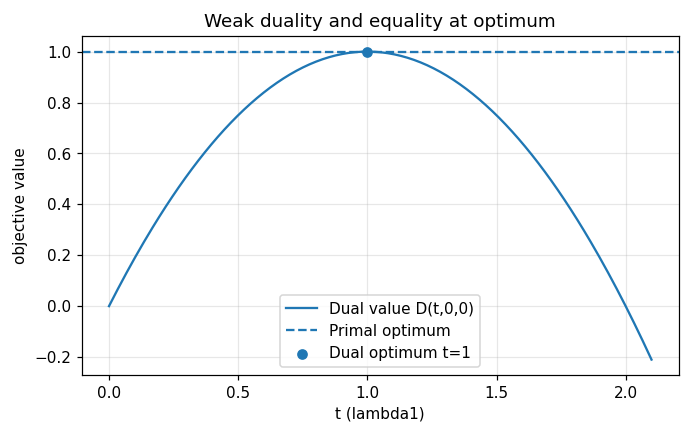

In [8]:
def dual_value(lam, c):
    q = a0 + A @ np.asarray(c)
    return q @ np.asarray(lam) - 0.5 * np.asarray(lam) @ H @ np.asarray(lam)

# 例題A.2で λ=(t,0,0), t>=0 を動かす（双対実行可能）
t = np.linspace(0, 2.1, 250)
D = np.array([dual_value([z,0,0], [2,4]) for z in t])
plt.figure(figsize=(7,4))
plt.plot(t,D,label='Dual value D(t,0,0)')
plt.axhline(case_A2['pval'],linestyle='--',label='Primal optimum')
plt.scatter([1],[dual_value([1,0,0],[2,4])],zorder=3,label='Dual optimum t=1')
plt.xlabel('t (lambda1)'); plt.ylabel('objective value'); plt.title('Weak duality and equality at optimum')
plt.grid(alpha=.3); plt.legend(); plt.show()
assert np.max(D) <= case_A2['pval'] + 1e-4

## 8. 発展：ヘッセ行列と固有値の関係

主問題 $f(x)=\tfrac12\|x-c\|^2$ のヘッセ行列は $I$ で、固有値はすべて1です。

双対関数 $D(\lambda)=q^T\lambda-\tfrac12\lambda^TH\lambda$ のヘッセ行列は $-H$ です。$H$ の固有値はすべて非負なので、$-H$ の固有値はすべて非正、つまり $D$ は**凹関数**です。

$H=AA^T$ は $3\times3$ ですが、$A$ は $3\times2$ なので $\mathrm{rank}(H)\le2$。**少なくとも1つの固有値は0**になります。したがって、双対関数は必ずしも厳密凹ではありません。

In [9]:
primal_hessian = np.eye(2)
dual_hessian = -H
print('主問題ヘッセ行列の固有値:', np.linalg.eigvalsh(primal_hessian))
print('双対目的関数ヘッセ行列の固有値:', np.linalg.eigvalsh(dual_hessian))
print('H の階数:', np.linalg.matrix_rank(H))

主問題ヘッセ行列の固有値: [1. 1.]
双対目的関数ヘッセ行列の固有値: [-28.593387  -4.406613  -0.      ]
H の階数: 2


## 9. 自主実験：自分で中心を変えてみる

次のセルの `c_custom` を変更してください。例えば `[-1,4]`、`[4,0]`、`[0,2]` など。

観察すべきこと：

1. 最適解は中心 $c$ と一致するか？
2. $\lambda_i>0$ の制約はどれか？
3. $\lambda_i=0$ と $g_i(x^*)<0$ の対応は成り立つか？
4. 双対ギャップは0に近いか？
5. 有効な制約が1個のケースと2個のケースで、最適点はどう違うか？

=== 自主実験 ===
中心 c                 = [4. 0.]
主問題の最適解 x*       = [3. 1.]
双対解 λ*              = [0.666667 0.       0.333333]
双対解から復元した x*    = [3. 1.]
制約 g_i(x*)           = [ 0. -9. -0.]
主問題の最小値         = 1.0000000000000004
双対問題の最大値       = 0.9999999999999999
双対ギャップ           = 5.551115123125783e-16
相補性 λ_i g_i(x*)      = [ 0. -0. -0.]
停留条件の残差         = [-0.  0.]
正の乗数の制約番号     = [np.int64(1), np.int64(3)]


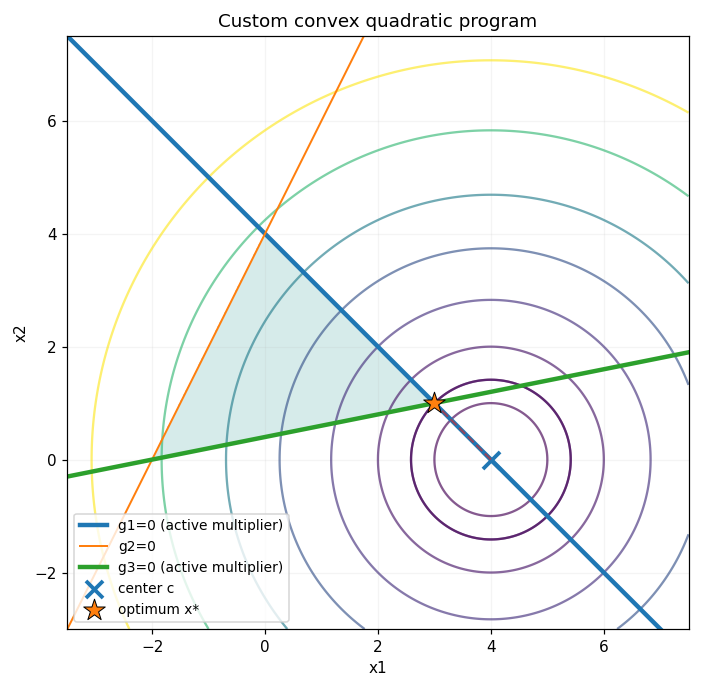

In [10]:
c_custom = np.array([4.0, 0.0])  # ここを書き換える
custom = analyze_case(c_custom, '自主実験')
plot_case(custom, 'Custom convex quadratic program')

## 10. 理解度確認の練習問題

**Q1.** 次の条件から $\lambda_2=0$ と言える理由を述べてください。

$$g_2(x^*)=-3,\quad \lambda_2g_2(x^*)=0.$$

**Q2.** $H=AA^T$ が半正定値であることを、任意のベクトル $v$ を使って証明してください。

**Q3.** 例題 A.2 において $x^*=(1,3)$ の目的関数値を手計算してください。

**Q4.** なぜ双対問題は $D(\lambda)$ を**最大化**するのでしょうか？ 弱双対性 $D(\lambda)\le f(x)$ を使って説明してください。

**Q5.** 例題 A.3 の $f_1$ ではなぜ $\lambda_2=0$、$\lambda_1,\lambda_3>0$ になるのでしょうか？

<details><summary>解答例（クリックして表示）</summary>

1. $-3\lambda_2=0$ なので $\lambda_2=0$。
2. $v^THv=v^TAA^Tv=\|A^Tv\|^2\ge0$。
3. $\tfrac12[(1-2)^2+(3-4)^2]=1$。
4. $D$ は主問題の最小値の下界なので、最大化するとできるだけ厳しい下界になる。
5. 最適点 $(3,1)$ では $g_1=g_3=0$ だが $g_2=-9<0$。停留条件から $\lambda_1=5/3,\lambda_3=1/3$、相補性から $\lambda_2=0$。

</details>

---

### 総まとめ

$$\boxed{
\begin{gathered}
\min_{x}\tfrac12\|x-c\|^2\quad(g_i(x)\le0)\\
\downarrow\ \text{ラグランジュ関数}\\
L(x,\lambda)=\tfrac12\|x-c\|^2+\lambda^T(a_0+Ax)\\
\downarrow\ \text{停留条件}\\
x=c-A^T\lambda\\
\downarrow\ \text{双対問題}\\
\max_{\lambda\ge0}\left(q^T\lambda-\tfrac12\lambda^TH\lambda\right)\\
\downarrow\ \text{復元とKKT検証}\\
x^*=c-A^T\lambda^*
\end{gathered}}
$$

**教科書との対応**：A.2.1〜A.2.7 → A.2.20〜A.2.27 → 例題A.2（A.2.32〜A.2.41）→ 例題A.3（A.2.42〜A.2.46）。